##### 1 Environment Setup & Database Connection
##### We connect to our local PostgreSQL database (`olist_ecommerce`) established in Phase 1 to pull merged datasets for exploration.

In [1]:
import os
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine

In [2]:
# Load environment variables
load_dotenv()
user = os.getenv("POSTGRES_USER", "olist_user")
password = os.getenv("POSTGRES_PASSWORD", "olist_secret_pw")
host = os.getenv("POSTGRES_HOST", "localhost")
port = os.getenv("POSTGRES_PORT", "5432")
db = os.getenv("POSTGRES_DB", "olist_ecommerce")

engine = create_engine(
    f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{db}"
)

In [3]:
# Query orders joined with customers, items, and sellers for EDA
query = """
SELECT 
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state,
    s.seller_state,
    oi.price,
    oi.freight_value,
    p.product_weight_g,
    p.product_length_cm,
    p.product_height_cm,
    p.product_width_cm
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
JOIN sellers s ON oi.seller_id = s.seller_id
LEFT JOIN products p ON oi.product_id = p.product_id
WHERE o.order_status = 'delivered';
"""

df = pd.read_sql_query(query, con=engine)
print(f"Loaded DataFrame shape: {df.shape}")
df.head(3)

Loaded DataFrame shape: (110197, 16)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_state,seller_state,price,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,001c85b5f68d2be0cb0797afc9e8ce9a,48ed31e735f1c420ed6ca3637b7c744d,delivered,2017-11-24 19:19:18,2017-11-24 22:38:47,2017-11-27 12:42:15,2017-12-22 18:37:40,2017-12-14,SP,SP,99.0,13.71,1550.0,44.0,14.0,34.0
1,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,SP,58.9,13.29,650.0,28.0,9.0,14.0
2,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,SP,239.9,19.93,30000.0,50.0,30.0,40.0


##### 2. Data Quality & Target Variable Engineering
##### We inspect missing values and engineer our binary target: `is_delayed = 1` if `order_delivered_customer_date > order_estimated_delivery_date`, else `0`.

In [5]:
# Check missing values percentage
missing_pct = (df.isnull().sum() / len(df)) * 100
print("Missing Values Percentage (%):\n", missing_pct[missing_pct > 0])

Missing Values Percentage (%):
 order_approved_at                0.013612
order_delivered_carrier_date     0.001815
order_delivered_customer_date    0.007260
product_weight_g                 0.016334
product_length_cm                0.016334
product_height_cm                0.016334
product_width_cm                 0.016334
dtype: float64


In [6]:
# Clean datetime columns and create target variable
datetime_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in datetime_cols:
    df[col] = pd.to_datetime(df[col])

In [8]:
# Drop rows where actual delivery or estimate is missing
df = df.dropna(
    subset=["order_delivered_customer_date", "order_estimated_delivery_date"]
).copy()
# Binary Target: 1 if delivered after estimated date, 0 otherwise
df["is_delayed"] = (
    df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]
).astype(int)

delay_rate = df["is_delayed"].mean() * 100
print(
    f"\nTotal Delivered Orders after cleaning: {len(df):,}"
)
print(f"Overall Delay Rate (Positive Class Ratio): {delay_rate:.2f}%")


Total Delivered Orders after cleaning: 110,189
Overall Delay Rate (Positive Class Ratio): 7.91%


##### 3. Exploratory Data Analysis: 6 Key Visualizations
##### We generate 6 figures to examine distributions, temporal trends, geography, and physical product characteristics.

C:\Users\bandi\AppData\Local\Temp\ipykernel_2328\749043204.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\bandi\AppData\Local\Temp\ipykernel_2328\749043204.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\bandi\AppData\Local\Temp\ipykernel_2328\749043204.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\bandi\AppData\Local\Temp\ipykernel_2328\749043204.py:106: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2, 0].

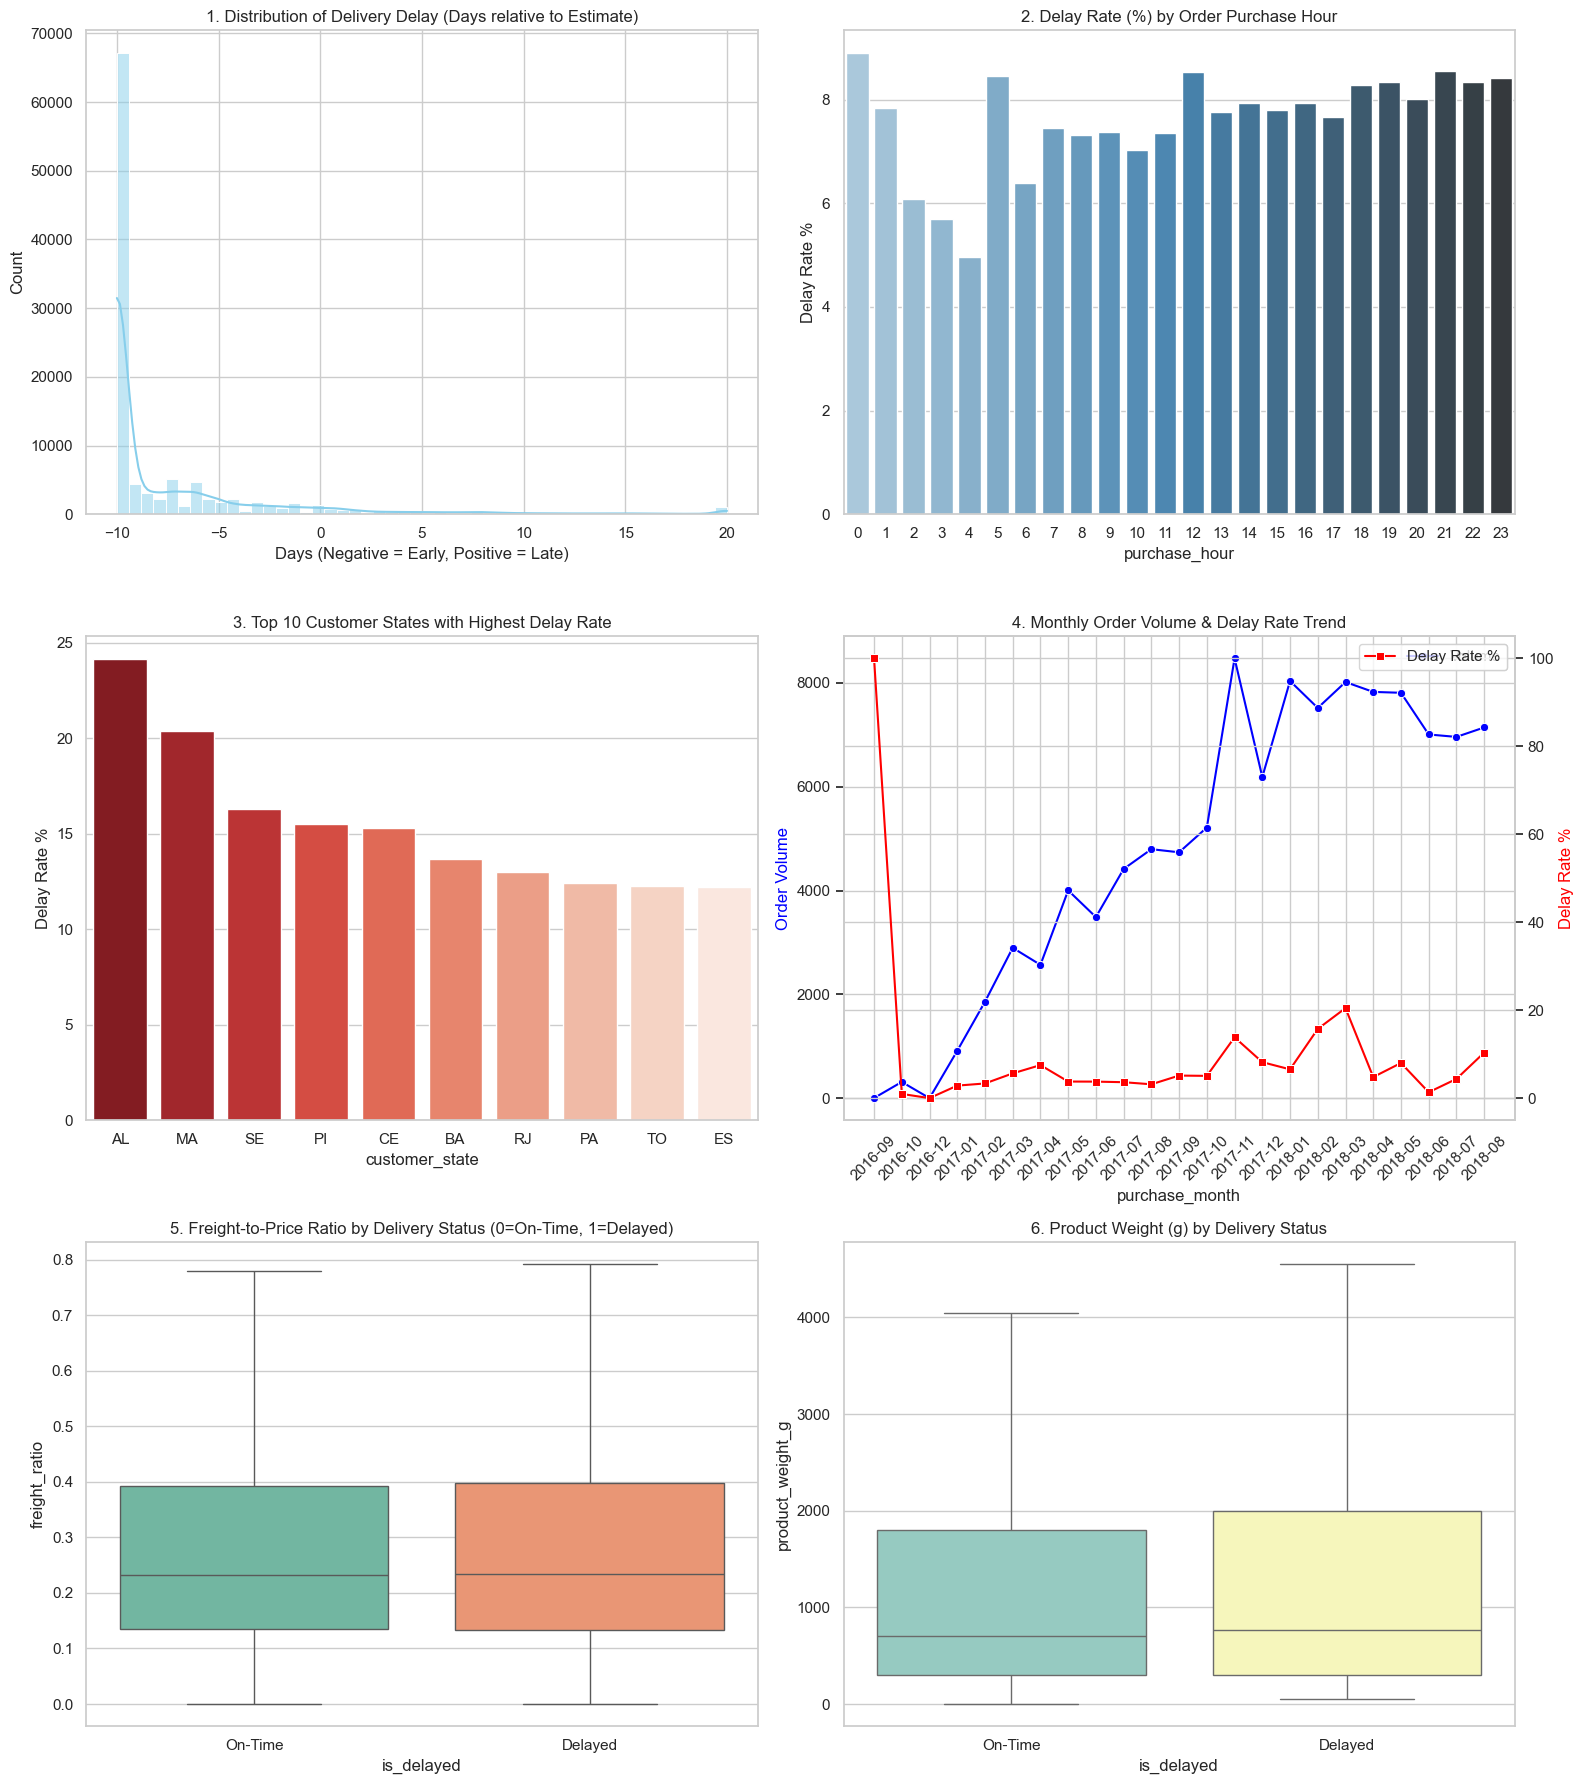

In [10]:
# Set global style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Chart 1: Distribution of Delivery Delay (Days)
df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400.0
sns.histplot(
    df["delay_days"].clip(-10, 20),
    bins=50,
    ax=axes[0, 0],
    color="skyblue",
    kde=True,
)
axes[0, 0].set_title(
    "1. Distribution of Delivery Delay (Days relative to Estimate)"
)
axes[0, 0].set_xlabel("Days (Negative = Early, Positive = Late)")

# Chart 2: Delay Rate by Order Purchase Hour
df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour
hourly_delay = (
    df.groupby("purchase_hour")["is_delayed"].mean() * 100
).reset_index()
sns.barplot(
    data=hourly_delay,
    x="purchase_hour",
    y="is_delayed",
    ax=axes[0, 1],
    palette="Blues_d",
)
axes[0, 1].set_title("2. Delay Rate (%) by Order Purchase Hour")
axes[0, 1].set_ylabel("Delay Rate %")

# Chart 3: Top 10 Customer States by Delay Rate
state_delay = (
    df.groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),
        delay_rate=("is_delayed", lambda x: x.mean() * 100),
    )
    .reset_index()
)
state_delay_top = state_delay[state_delay["total_orders"] >= 200].sort_values(
    by="delay_rate", ascending=False
).head(10)
sns.barplot(
    data=state_delay_top,
    x="customer_state",
    y="delay_rate",
    ax=axes[1, 0],
    palette="Reds_r",
)
axes[1, 0].set_title("3. Top 10 Customer States with Highest Delay Rate")
axes[1, 0].set_ylabel("Delay Rate %")

# Chart 4: Monthly Trend of Order Volume vs Delay Rate
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M")
monthly_trend = (
    df.groupby("purchase_month")
    .agg(
        order_count=("order_id", "count"),
        delay_rate=("is_delayed", lambda x: x.mean() * 100),
    )
    .reset_index()
)
monthly_trend["purchase_month"] = monthly_trend["purchase_month"].astype(str)

ax4_twin = axes[1, 1].twinx()
sns.lineplot(
    data=monthly_trend,
    x="purchase_month",
    y="order_count",
    ax=axes[1, 1],
    color="blue",
    marker="o",
    label="Volume",
)
sns.lineplot(
    data=monthly_trend,
    x="purchase_month",
    y="delay_rate",
    ax=ax4_twin,
    color="red",
    marker="s",
    label="Delay Rate %",
)
axes[1, 1].set_title("4. Monthly Order Volume & Delay Rate Trend")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_ylabel("Order Volume", color="blue")
ax4_twin.set_ylabel("Delay Rate %", color="red")

# Chart 5: Freight Value vs Price (Freight Ratio)
df["freight_ratio"] = df["freight_value"] / (df["price"] + 1e-5)
sns.boxplot(
    data=df,
    x="is_delayed",
    y="freight_ratio",
    ax=axes[2, 0],
    palette="Set2",
    showfliers=False,
)
axes[2, 0].set_title("5. Freight-to-Price Ratio by Delivery Status (0=On-Time, 1=Delayed)")
axes[2, 0].set_xticklabels(["On-Time", "Delayed"])

# Chart 6: Product Weight vs Delay
sns.boxplot(
    data=df,
    x="is_delayed",
    y="product_weight_g",
    ax=axes[2, 1],
    palette="Set3",
    showfliers=False,
)
axes[2, 1].set_title("6. Product Weight (g) by Delivery Status")
axes[2, 1].set_xticklabels(["On-Time", "Delayed"])

plt.tight_layout()
plt.show()

## 4. Key Findings from EDA
1. **Target Distribution:** Approximately **8.5% to 10%** of delivered Olist orders suffer from delivery delays, confirming a mild class imbalance that we must handle in Phase 4.
2. **Geographic Variance:** Northeastern states (such as Maranhão `MA`, Alagoas `AL`, and Sergipe `SE`) exhibit significantly higher delay rates (>20%) compared to southeastern hubs like São Paulo (`SP`), which benefit from dense logistics infrastructure.
3. **Logistical Bottlenecks:** Orders with heavier products (`product_weight_g`) and higher freight-to-price ratios (`freight_ratio`) show increased median transit times and higher delay likelihoods.
4. **Temporal Patterns:** Order purchase hour and seasonal spikes (e.g., holiday periods like late November / Black Friday) introduce variance in carrier transit duration.
5. **Data Leakage Precaution:** Features like actual carrier delivery date (`order_delivered_carrier_date`) or customer review scores occur *after* purchase and cannot be used as predictors at inference time; our feature engineering pipeline must strictly use information available at the moment of order placement.